In [7]:
from google.colab import files

uploaded = files.upload()

Saving paddy_predictions.csv to paddy_predictions (1).csv
Saving paddy_yield_random_forest.pkl to paddy_yield_random_forest (2).pkl


MODEL EVALUATION RESULTS
------------------------
Number of test records: 468
MAE: 180.67 kg/ha
RMSE: 231.02 kg/ha
R2 Score: 0.3997


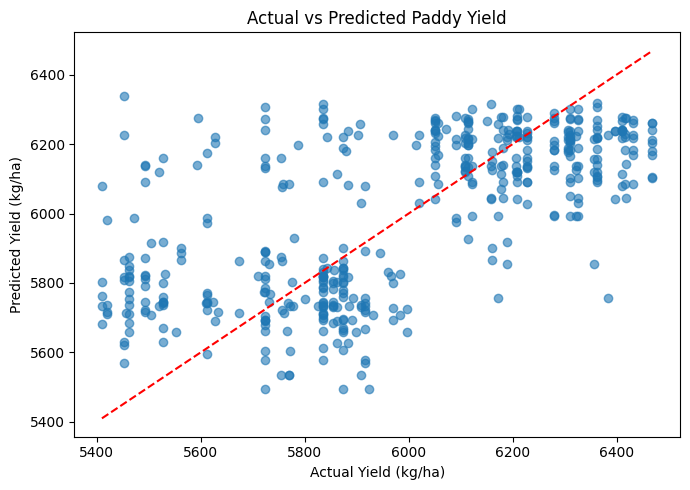

In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load uploaded prediction results
df = pd.read_csv("paddy_predictions.csv")

# Extract actual and predicted values
y_test = df["Actual Yield (kg/ha)"]
y_pred = df["Predicted Yield (kg/ha)"]

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print(f"Number of test records: {len(df)}")
print(f"MAE: {mae:.2f} kg/ha")
print(f"RMSE: {rmse:.2f} kg/ha")
print(f"R2 Score: {r2:.4f}")

# Actual vs Predicted graph
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.6)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], "r--")
plt.xlabel("Actual Yield (kg/ha)")
plt.ylabel("Predicted Yield (kg/ha)")
plt.title("Actual vs Predicted Paddy Yield")
plt.tight_layout()
plt.show()


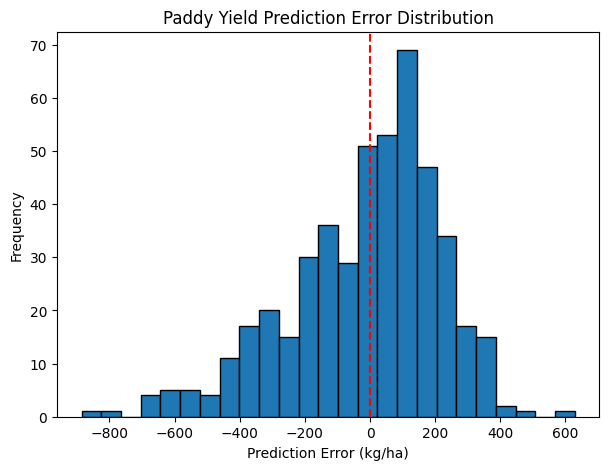

Mean Absolute Error: 180.6743960674708
Root Mean Squared Error: 231.01975868829496
R2 Score: 0.39966473241978673


In [9]:

# Prediction Error Analysis

errors = y_test - y_pred

plt.figure(figsize=(7, 5))
plt.hist(errors, bins=25, edgecolor="black")
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Prediction Error (kg/ha)")
plt.ylabel("Frequency")
plt.title("Paddy Yield Prediction Error Distribution")
plt.show()

print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("Root Mean Squared Error:",
      np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))


In [4]:

# MODEL EVALUATION

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    explained_variance_score
)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
evs = explained_variance_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("=" * 35)
print(f"MAE                 : {mae:.2f} kg/ha")
print(f"RMSE                : {rmse:.2f} kg/ha")
print(f"R2 Score            : {r2:.4f}")
print(f"Explained Variance  : {evs:.4f}")

# Graph 1: Actual vs Predicted Yield
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.6)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], 'r--')

plt.xlabel("Actual Yield (kg/ha)")
plt.ylabel("Predicted Yield (kg/ha)")
plt.title("Actual vs Predicted Paddy Yield")
plt.tight_layout()
plt.show()

# Graph 2: Prediction Error Distribution
errors = np.asarray(y_test) - np.asarray(y_pred)

plt.figure(figsize=(7, 5))
plt.hist(errors, bins=25, edgecolor="black")
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Prediction Error (kg/ha)")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")
plt.tight_layout()
plt.show()

# Graph 3: Residual Plot
plt.figure(figsize=(7, 5))
plt.scatter(y_pred, errors, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Yield (kg/ha)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Analysis")
plt.tight_layout()
plt.show()


NameError: name 'y_test' is not defined

In [ ]:
import pandas as pd

df = pd.read_csv('paddy_preprocessed.csv')

print("Dataset shape:", df.shape)
df.head()

In [ ]:
print(df['Paddy yield(in Kg)'].describe())

In [ ]:
print(df.columns.tolist())

In [ ]:
# Separate features and target

X = df.drop('Paddy yield(in Kg)', axis=1)
y = df['Paddy yield(in Kg)']

print("X shape:", X.shape)
print("y shape:", y.shape)

In [ ]:
print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

In [ ]:
from sklearn.linear_model import LinearRegression

# Create the model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

In [ ]:
# Make predictions on test data
y_pred = lr_model.predict(X_test)

# Show first 10 predictions
for actual, predicted in zip(y_test[:10], y_pred[:10]):
    print(f"Actual: {actual:.2f} | Predicted: {predicted:.2f}")

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Linear Regression Performance")
print("--------------------------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

In [ ]:
import pandas as pd

# Correlation with the target
correlation = df.corr(numeric_only=True)['Paddy yield(in Kg)'].sort_values(
    ascending=False
)

print(correlation)

In [ ]:
# Check the values of the highly correlated features and the target

cols = [
    'Paddy yield(in Kg)',
    'Pest_60Day(in ml)',
    'Urea_40Days',
    'Hectares ',
    'LP_nurseryarea(in Tonnes)'
]

df[cols].head(20)

In [ ]:
df[cols].describe()

In [ ]:
# Check the relationship between yield and hectares

df.groupby('Hectares ')['Paddy yield(in Kg)'].agg(
    ['count', 'mean', 'min', 'max']
)

In [ ]:
# Calculate yield per hectare

df['Yield_per_hectare'] = df['Paddy yield(in Kg)'] / df['Hectares ']

df['Yield_per_hectare'].describe()

In [ ]:
# Correlation of yield per hectare with hectares

print(
    df[['Hectares ', 'Yield_per_hectare']].corr()
)

In [ ]:
df['Yield_per_hectare'].describe()

In [ ]:
df[['Hectares ', 'Paddy yield(in Kg)', 'Yield_per_hectare']].head(10)

In [ ]:
# Create yield per hectare
df['Yield_per_hectare'] = (
    df['Paddy yield(in Kg)'] / df['Hectares ']
)

# Remove target and columns directly related to calculating it
columns_to_remove = [
    'Paddy yield(in Kg)',
    'Hectares ',
    'LP_nurseryarea(in Tonnes)',
    'Urea_40Days',
    'Pest_60Day(in ml)'
]

X = df.drop(columns=columns_to_remove + ['Yield_per_hectare'])
y = df['Yield_per_hectare']

print("X shape:", X.shape)
print("y shape:", y.shape)

In [ ]:
print("Target:", y.name)
print("Number of features:", X.shape[1])

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

In [ ]:
from sklearn.linear_model import LinearRegression

# Create Linear Regression model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train_scaled, y_train)

print("Linear Regression model trained successfully!")

In [ ]:
y_pred_lr = lr_model.predict(X_test_scaled)

print("First 10 predictions:")
for actual, predicted in zip(y_test.iloc[:10], y_pred_lr[:10]):
    print(f"Actual: {actual:.2f} | Predicted: {predicted:.2f}")

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression Performance")
print("--------------------------------")
print(f"MAE : {mae_lr:.2f}")
print(f"RMSE: {rmse_lr:.2f}")
print(f"R²  : {r2_lr:.4f}")

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

In [ ]:
X_train

In [ ]:
X_train_scaled

In [ ]:
y_pred_rf = rf_model.predict(X_test)

print("First 10 predictions:")
for actual, predicted in zip(y_test.iloc[:10], y_pred_rf[:10]):
    print(f"Actual: {actual:.2f} | Predicted: {predicted:.2f}")

In [ ]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Performance")
print("--------------------------------")
print(f"MAE : {mae_rf:.2f}")
print(f"RMSE: {rmse_rf:.2f}")
print(f"R²  : {r2_rf:.4f}")

In [ ]:
# ============================================================
# PADDY YIELD PER HECTARE PREDICTION
# FINAL RANDOM FOREST MODEL
# ============================================================

# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ============================================================
# 2. Upload preprocessed dataset
# ============================================================

uploaded = files.upload()

df = pd.read_csv('paddy_preprocessed.csv')

print("Dataset loaded successfully!")
print("Original shape:", df.shape)


# ============================================================
# 3. Create target: Yield per hectare
# ============================================================

df['Yield_per_hectare'] = (
    df['Paddy yield(in Kg)'] / df['Hectares ']
)

print("\nYield per hectare created.")


# ============================================================
# 4. Remove columns that should not be used as features
# ============================================================

columns_to_remove = [
    'Paddy yield(in Kg)',
    'Hectares ',
    'LP_nurseryarea(in Tonnes)',
    'Urea_40Days',
    'Pest_60Day(in ml)',
    'Yield_per_hectare'
]

X = df.drop(columns=columns_to_remove)
y = df['Yield_per_hectare']

print("\nFeatures:", X.shape)
print("Target:", y.shape)


# ============================================================
# 5. Train / Test Split
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTrain/Test Split")
print("----------------")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


# ============================================================
# 6. Train Random Forest
# ============================================================

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("\nRandom Forest trained successfully!")


# ============================================================
# 7. Make predictions
# ============================================================

y_pred = rf_model.predict(X_test)


# ============================================================
# 8. Evaluate the model
# ============================================================

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n===================================")
print("FINAL RANDOM FOREST PERFORMANCE")
print("===================================")
print(f"MAE  : {mae:.2f} kg/ha")
print(f"RMSE : {rmse:.2f} kg/ha")
print(f"R²   : {r2:.4f}")
print("===================================")


# ============================================================
# 9. Show actual vs predicted values
# ============================================================

results = pd.DataFrame({
    'Actual Yield (kg/ha)': y_test.values,
    'Predicted Yield (kg/ha)': y_pred
})

print("\nFirst 10 Predictions:")
print(results.head(10))


# ============================================================
# 10. Feature Importance
# ============================================================

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("\nTop 15 Important Features:")
print(feature_importance.head(15))


# ============================================================
# 11. Plot Feature Importance
# ============================================================

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'][::-1],
    top_features['Importance'][::-1]
)

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 15 Features Affecting Paddy Yield per Hectare')

plt.tight_layout()
plt.show()


# ============================================================
# 12. Actual vs Predicted Plot
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xlabel('Actual Yield (kg/ha)')
plt.ylabel('Predicted Yield (kg/ha)')
plt.title('Actual vs Predicted Paddy Yield')

plt.tight_layout()
plt.show()


# ============================================================
# 13. Save predictions
# ============================================================

results.to_csv(
    '/content/paddy_predictions.csv',
    index=False
)

print("\nPredictions saved as paddy_predictions.csv")


# ============================================================
# 14. Save feature importance
# ============================================================

feature_importance.to_csv(
    '/content/feature_importance.csv',
    index=False
)

print("Feature importance saved as feature_importance.csv")


# ============================================================
# 15. Save trained model
# ============================================================

import joblib

joblib.dump(
    rf_model,
    '/content/paddy_yield_random_forest.pkl'
)

print("Model saved as paddy_yield_random_forest.pkl")


# ============================================================
# 16. Download files
# ============================================================

files.download('/content/paddy_predictions.csv')
files.download('/content/feature_importance.csv')
files.download('/content/paddy_yield_random_forest.pkl')

print("\nAll files are ready for download!")